# AI Developer Assignment — Travel Reimbursement Approval Agent

**Candidate:** Abhijeet Tayade  
**Assignment:** Travel Reimbursement Approval Agent

## Objective

This notebook implements a lightweight Agentic AI workflow that evaluates travel reimbursement claims against the supplied policy.

The design deliberately separates:
- **Agent reasoning / orchestration** — determines which checks are needed.
- **Deterministic tools** — perform policy, receipt, limit, and approval calculations.
- **Validation** — prevents malformed or unsupported final decisions.
- **Dashboard** — summarizes the actual generated outcomes.

The solution is intentionally lightweight and self-contained so it can run top-to-bottom without requiring external services.


## Setup / README

### How to run
1. Open this notebook in Jupyter Notebook, JupyterLab, Google Colab, or VS Code.
2. Run all cells from top to bottom.
3. No manual configuration or API key is required.
4. The final cell prints the required JSON array for all five supplied claims.

### Optional GenAI integration
The notebook includes an optional OpenAI-compatible tool-calling example in a separate section. The core evaluation does not depend on an external API, which keeps the demo reproducible and runnable in a clean environment.

### Design choice
Financial reimbursement calculations are deterministic by design. An LLM can interpret claims and select tools, but it should not invent policy limits or perform unchecked financial calculations.


## Architecture

```text
Claim Input
    |
    v
Agent Controller
    |
    +--> Policy Lookup
    +--> Receipt Completeness Check
    +--> Limit / Per-Diem Checker
    +--> Approval Threshold Checker
    +--> Timeliness Checker
    |
    v
Decision Engine
    |
    +--> APPROVE
    +--> PARTIAL_APPROVE
    +--> REJECT
    +--> MANUAL_REVIEW
    |
    v
Output Validator
    |
    v
Structured JSON + Dashboard
```

### Safety / reliability principle

The agent prefers **MANUAL_REVIEW** when information is incomplete, a policy exception exists, or approval authority is exceeded.


In [22]:
import json
from datetime import datetime
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

print("Environment ready.")


Environment ready.


## 1. Policy Knowledge Base

The policy IDs below are taken directly from Appendix A of the assignment. They are retained as stable references so every decision can be traced back to the supplied policy.


In [23]:
POLICIES = {
    "POL-CAT-01": {
        "description": "Eligible categories",
        "eligible_categories": [
            "airfare", "lodging", "meals",
            "ground_transport", "conference_fees"
        ]
    },
    "POL-CAT-02": {
        "description": "Ineligible items",
        "ineligible_categories": [
            "alcohol", "minibar", "spa", "gym",
            "personal_entertainment", "in_room_movies",
            "personal_shopping", "gifts",
            "traffic_fines", "penalties", "late_fees",
            "personal_expense"
        ]
    },
    "POL-PD-01": {
        "description": "Meals maximum $75 per day",
        "category": "meals",
        "limit": 75
    },
    "POL-PD-02": {
        "description": "Lodging maximum $200 per night",
        "category": "lodging",
        "limit": 200
    },
    "POL-PD-03": {
        "description": "Ground transport maximum $50 per day",
        "category": "ground_transport",
        "limit": 50
    },
    "POL-AIR-01": {
        "description": "Only economy airfare is reimbursable; business/first class requires Manual Review",
        "allowed_class": "economy"
    },
    "POL-RCT-01": {
        "description": "Receipt required above $25; airfare and lodging always require a receipt"
    },
    "POL-RCT-02": {
        "description": "Missing required receipt routes the claim to Manual Review"
    },
    "POL-APR-01": {
        "description": "Total reimbursable amount <= $500"
    },
    "POL-APR-02": {
        "description": "Total reimbursable amount > $500 and <= $2,000"
    },
    "POL-APR-03": {
        "description": "Total reimbursable amount > $2,000 requires Manual Review"
    },
    "POL-TIME-01": {
        "description": "Claim must be submitted within 30 days of the expense date"
    }
}

CATEGORY_LIMITS = {
    "meals": {"limit": 75, "policy_ref": "POL-PD-01"},
    "lodging": {"limit": 200, "policy_ref": "POL-PD-02"},
    "ground_transport": {"limit": 50, "policy_ref": "POL-PD-03"},
}


## 2. Agent Tools

The assignment requires at least two meaningful tools. This implementation uses five:

1. `policy_lookup`
2. `check_receipts`
3. `check_limits`
4. `check_approval_threshold`
5. `check_timeliness`

The agent controller selects the relevant tools based on claim contents.


In [24]:
def policy_lookup(query: str) -> dict:
    """Retrieve policy rules relevant to the supplied claim context."""
    q = query.lower()
    matched = {}

    if any(x in q for x in ["meal", "food", "dinner"]):
        matched["POL-PD-01"] = POLICIES["POL-PD-01"]

    if any(x in q for x in ["lodging", "hotel"]):
        matched["POL-PD-02"] = POLICIES["POL-PD-02"]

    if any(x in q for x in ["ground", "taxi", "rideshare", "train", "parking", "rental"]):
        matched["POL-PD-03"] = POLICIES["POL-PD-03"]

    if any(x in q for x in ["airfare", "flight", "economy", "business class", "first class"]):
        matched["POL-AIR-01"] = POLICIES["POL-AIR-01"]

    if "receipt" in q:
        matched["POL-RCT-01"] = POLICIES["POL-RCT-01"]
        matched["POL-RCT-02"] = POLICIES["POL-RCT-02"]

    matched["POL-CAT-01"] = POLICIES["POL-CAT-01"]
    matched["POL-CAT-02"] = POLICIES["POL-CAT-02"]
    matched["POL-APR-01"] = POLICIES["POL-APR-01"]
    matched["POL-APR-02"] = POLICIES["POL-APR-02"]
    matched["POL-APR-03"] = POLICIES["POL-APR-03"]
    matched["POL-TIME-01"] = POLICIES["POL-TIME-01"]

    return matched


def check_receipts(claim: dict) -> dict:
    """Check receipt requirements from POL-RCT-01 / POL-RCT-02."""
    missing_docs = []

    for item in claim["items"]:
        required = (
            item["amount"] > 25
            or item["category"] in {"airfare", "lodging"}
        )
        if required and not item["receipt_attached"]:
            missing_docs.append(f'{item["category"]} receipt')

    return {
        "complete": len(missing_docs) == 0,
        "missing_docs": missing_docs,
        "policy_refs": ["POL-RCT-01", "POL-RCT-02"]
    }


def check_limits(item: dict) -> dict:
    """Apply applicable per-diem/category limits."""
    category = item["category"]

    if category not in CATEGORY_LIMITS:
        return {
            "approved_amount": item["amount"],
            "deducted_amount": 0.0,
            "policy_ref": None,
            "within_limit": True
        }

    config = CATEGORY_LIMITS[category]
    quantity = item.get("quantity", 1)
    maximum = config["limit"] * quantity
    amount = item["amount"]

    approved = min(amount, maximum)
    deducted = max(0.0, amount - maximum)

    return {
        "approved_amount": approved,
        "deducted_amount": deducted,
        "policy_ref": config["policy_ref"],
        "within_limit": deducted == 0
    }


def check_approval_threshold(amount: float) -> dict:
    """Determine approval authority from the reimbursable amount."""
    if amount <= 500:
        return {"tier": "AUTO_APPROVE", "policy_ref": "POL-APR-01", "manual_review": False}
    if amount <= 2000:
        return {"tier": "MANAGER", "policy_ref": "POL-APR-02", "manual_review": False}
    return {"tier": "DIRECTOR", "policy_ref": "POL-APR-03", "manual_review": True}


def check_timeliness(claim: dict) -> dict:
    """Check POL-TIME-01's 30-day submission window."""
    expense_date = datetime.strptime(claim["expense_date"], "%Y-%m-%d")
    submitted_date = datetime.strptime(claim["submitted_date"], "%Y-%m-%d")
    elapsed = (submitted_date - expense_date).days

    return {
        "within_30_days": elapsed <= 30,
        "days_elapsed": elapsed,
        "policy_ref": "POL-TIME-01"
    }


## 3. Agent Decision Policy

The controller follows this priority:

1. Ineligible-only claim → `REJECT`
2. Explicit exception / missing required receipt / late claim → `MANUAL_REVIEW`
3. Reimbursable amount > $2,000 → `MANUAL_REVIEW`
4. Valid expenses with deductions → `PARTIAL_APPROVE`
5. Fully compliant claim → `APPROVE`

This ordering prevents the agent from forcing a definitive reimbursement decision when the policy requires human review.


In [25]:
REQUIRED_FIELDS = {
    "claim_id",
    "decision",
    "approved_amount",
    "deducted_amount",
    "missing_docs",
    "policy_refs",
    "confidence",
    "explanation",
    "tools_used",
}

VALID_DECISIONS = {
    "APPROVE",
    "PARTIAL_APPROVE",
    "REJECT",
    "MANUAL_REVIEW",
}


def build_result(
    claim_id,
    decision,
    approved_amount,
    deducted_amount,
    missing_docs,
    policy_refs,
    confidence,
    explanation,
    tools_used,
):
    return {
        "claim_id": claim_id,
        "decision": decision,
        "approved_amount": round(float(approved_amount), 2),
        "deducted_amount": round(float(deducted_amount), 2),
        "missing_docs": sorted(set(missing_docs)),
        "policy_refs": sorted(set(policy_refs)),
        "confidence": round(float(confidence), 2),
        "explanation": explanation,
        "tools_used": sorted(set(tools_used)),
    }


def validate_result(result: dict) -> bool:
    assert set(result.keys()) == REQUIRED_FIELDS
    assert result["decision"] in VALID_DECISIONS
    assert result["approved_amount"] >= 0
    assert result["deducted_amount"] >= 0
    assert 0 <= result["confidence"] <= 1
    assert isinstance(result["missing_docs"], list)
    assert isinstance(result["policy_refs"], list)
    assert isinstance(result["tools_used"], list)
    return True


def travel_reimbursement_agent(claim: dict) -> dict:
    """Agentic controller: selects and combines deterministic tools."""

    tools_used = []
    policy_refs = set()
    missing_docs = []
    review_reasons = []

    # Context grounding
    claim_text = " ".join(
        [item["category"] + " " + item.get("description", "") for item in claim["items"]]
    )
    retrieved_policy = policy_lookup(claim_text + " receipt")
    tools_used.append("policy_lookup")
    policy_refs.update(retrieved_policy.keys())

    # Receipt tool
    receipt_result = check_receipts(claim)
    tools_used.append("check_receipts")
    missing_docs.extend(receipt_result["missing_docs"])
    if missing_docs:
        review_reasons.append("Required receipt is missing")

    # Timeliness tool
    time_result = check_timeliness(claim)
    tools_used.append("check_timeliness")
    policy_refs.add(time_result["policy_ref"])
    if not time_result["within_30_days"]:
        review_reasons.append("Claim was submitted more than 30 days after the expense date")

    approved_amount = 0.0
    deducted_amount = 0.0
    has_partial_deduction = False
    eligible_count = 0
    ineligible_count = 0

    for item in claim["items"]:
        category = item["category"]
        amount = item["amount"]

        # Explicitly ineligible categories
        if category in POLICIES["POL-CAT-02"]["ineligible_categories"]:
            ineligible_count += 1
            policy_refs.add("POL-CAT-02")
            deducted_amount += amount
            continue

        eligible_count += 1
        policy_refs.add("POL-CAT-01")

        # Airfare exception
        if category == "airfare":
            policy_refs.add("POL-AIR-01")
            airfare_class = item.get("class", "economy")
            if airfare_class != "economy":
                review_reasons.append(
                    "Business/first-class airfare requires Manual Review because pre-approval may exist"
                )
                continue

        # Category limit
        limit_result = check_limits(item)
        tools_used.append("check_limits")
        if limit_result["policy_ref"]:
            policy_refs.add(limit_result["policy_ref"])

        approved_amount += limit_result["approved_amount"]
        deducted_amount += limit_result["deducted_amount"]

        if limit_result["deducted_amount"] > 0:
            has_partial_deduction = True

    # If there are no eligible items, reject the entire claim.
    if eligible_count == 0 and ineligible_count > 0:
        result = build_result(
            claim["claim_id"],
            "REJECT",
            0.0,
            deducted_amount,
            missing_docs,
            policy_refs,
            0.99,
            "All claimed items are explicitly ineligible under POL-CAT-02.",
            tools_used,
        )
        validate_result(result)
        return result

    # Explicit manual-review conditions take priority.
    if review_reasons:
        result = build_result(
            claim["claim_id"],
            "MANUAL_REVIEW",
            0.0,
            0.0,
            missing_docs,
            policy_refs,
            0.97,
            "Manual review required: " + "; ".join(sorted(set(review_reasons))) + ".",
            tools_used,
        )
        validate_result(result)
        return result

    # Approval threshold applies after per-diem deductions.
    threshold = check_approval_threshold(approved_amount)
    tools_used.append("check_approval_threshold")
    policy_refs.add(threshold["policy_ref"])

    if threshold["manual_review"]:
        result = build_result(
            claim["claim_id"],
            "MANUAL_REVIEW",
            0.0,
            0.0,
            missing_docs,
            policy_refs,
            0.98,
            "Reimbursable amount exceeds the agent's $2,000 approval authority.",
            tools_used,
        )
        validate_result(result)
        return result

    if has_partial_deduction:
        decision = "PARTIAL_APPROVE"
        explanation = (
            "Claim is eligible, but amounts above applicable per-diem/category limits "
            "were deducted according to policy."
        )
        confidence = 0.98
    else:
        decision = "APPROVE"
        explanation = (
            "Claim is fully compliant with the supplied reimbursement policy and "
            "falls within an approvable approval tier."
        )
        confidence = 0.99

    result = build_result(
        claim["claim_id"],
        decision,
        approved_amount,
        deducted_amount,
        missing_docs,
        policy_refs,
        confidence,
        explanation,
        tools_used,
    )
    validate_result(result)
    return result


## 4. Supplied Sample Claims

These are the five claims from Appendix B. No additional claim set is introduced.


In [26]:
claims = [
    {
        "claim_id": "CLM-001",
        "expense_date": "2026-06-12",
        "submitted_date": "2026-06-20",
        "items": [
            {"category": "airfare", "description": "Round-trip economy airfare",
             "amount": 420.00, "receipt_attached": True, "class": "economy"},
            {"category": "lodging", "description": "Hotel, 2 nights @ $180",
             "amount": 360.00, "quantity": 2, "receipt_attached": True},
            {"category": "meals", "description": "Meals, 3 days @ ~$60/day",
             "amount": 180.00, "quantity": 3, "receipt_attached": True},
            {"category": "conference_fees", "description": "Conference registration",
             "amount": 150.00, "receipt_attached": True},
        ],
    },
    {
        "claim_id": "CLM-002",
        "expense_date": "2026-06-15",
        "submitted_date": "2026-06-25",
        "items": [
            {"category": "spa", "description": "Hotel spa package",
             "amount": 300.00, "receipt_attached": True},
            {"category": "minibar", "description": "In-room minibar",
             "amount": 80.00, "receipt_attached": True},
        ],
    },
    {
        "claim_id": "CLM-003",
        "expense_date": "2026-06-10",
        "submitted_date": "2026-06-22",
        "items": [
            {"category": "airfare", "description": "Round-trip economy airfare",
             "amount": 300.00, "receipt_attached": True, "class": "economy"},
            {"category": "lodging", "description": "Hotel, 2 nights @ $250",
             "amount": 500.00, "quantity": 2, "receipt_attached": True},
            {"category": "meals", "description": "Meals, 2 days @ $70/day",
             "amount": 140.00, "quantity": 2, "receipt_attached": True},
        ],
    },
    {
        "claim_id": "CLM-004",
        "expense_date": "2026-06-18",
        "submitted_date": "2026-06-28",
        "items": [
            {"category": "airfare", "description": "Business-class international airfare",
             "amount": 2400.00, "receipt_attached": True, "class": "business"},
            {"category": "lodging", "description": "Hotel, 3 nights",
             "amount": 600.00, "quantity": 3, "receipt_attached": False},
        ],
    },
    {
        "claim_id": "CLM-005",
        "expense_date": "2026-06-11",
        "submitted_date": "2026-06-24",
        "items": [
            {"category": "meals", "description": "Client dinner for 4 (business development)",
             "amount": 220.00, "quantity": 1, "receipt_attached": False},
        ],
    },
]


## 5. Run Agent

The following execution generates one structured result per supplied claim.


In [27]:
results = [travel_reimbursement_agent(claim) for claim in claims]

for result in results:
    print(
        result["claim_id"],
        "->",
        result["decision"],
        "| approved =", result["approved_amount"],
        "| deducted =", result["deducted_amount"]
    )


CLM-001 -> APPROVE | approved = 1110.0 | deducted = 0.0
CLM-002 -> REJECT | approved = 0.0 | deducted = 380.0
CLM-003 -> PARTIAL_APPROVE | approved = 840.0 | deducted = 100.0
CLM-004 -> MANUAL_REVIEW | approved = 0.0 | deducted = 0.0
CLM-005 -> MANUAL_REVIEW | approved = 0.0 | deducted = 0.0


## 6. Tool-Use / Audit Trace

This view makes the agent's tool usage visible for interview/demo purposes.


In [28]:
audit_df = pd.DataFrame([
    {
        "claim_id": r["claim_id"],
        "decision": r["decision"],
        "tools_used": ", ".join(r["tools_used"]),
        "policy_refs": ", ".join(r["policy_refs"]),
        "missing_docs": ", ".join(r["missing_docs"]) if r["missing_docs"] else "None",
        "confidence": r["confidence"],
    }
    for r in results
])

display(audit_df)


,claim_id,decision,tools_used,policy_refs,missing_docs,confidence
0,CLM-001,APPROVE,"check_approval_threshold, check_limits, check_...","POL-AIR-01, POL-APR-01, POL-APR-02, POL-APR-03...",None,0.99
1,CLM-002,REJECT,"check_receipts, check_timeliness, policy_lookup","POL-APR-01, POL-APR-02, POL-APR-03, POL-CAT-01...",None,0.99
2,CLM-003,PARTIAL_APPROVE,"check_approval_threshold, check_limits, check_...","POL-AIR-01, POL-APR-01, POL-APR-02, POL-APR-03...",None,0.98
3,CLM-004,MANUAL_REVIEW,"check_limits, check_receipts, check_timeliness...","POL-AIR-01, POL-APR-01, POL-APR-02, POL-APR-03...",lodging receipt,0.97
4,CLM-005,MANUAL_REVIEW,"check_limits, check_receipts, check_timeliness...","POL-APR-01, POL-APR-02, POL-APR-03, POL-CAT-01...",meals receipt,0.97


## 7. Dashboard

The dashboard is derived from the actual agent results rather than hard-coded values.


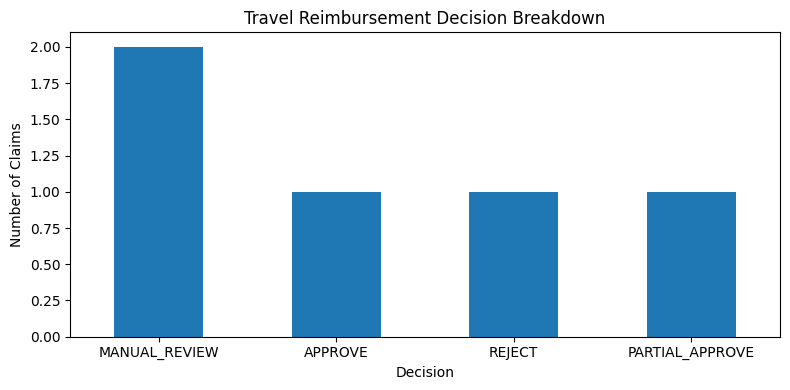

,Metric,Value
0,Total claims,5.0
1,Approved amount,1950.0
2,Deducted amount,480.0
3,Manual review cases,2.0


In [29]:
results_df = pd.DataFrame(results)

decision_counts = results_df["decision"].value_counts()

plt.figure(figsize=(8, 4))
decision_counts.plot(kind="bar")
plt.title("Travel Reimbursement Decision Breakdown")
plt.xlabel("Decision")
plt.ylabel("Number of Claims")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Metric": [
        "Total claims",
        "Approved amount",
        "Deducted amount",
        "Manual review cases",
    ],
    "Value": [
        len(results_df),
        results_df["approved_amount"].sum(),
        results_df["deducted_amount"].sum(),
        int((results_df["decision"] == "MANUAL_REVIEW").sum()),
    ]
})

display(summary)


## 8. Optional LLM Tool-Calling Layer

For an environment with an LLM API, the same deterministic tools can be exposed as function/tool calls. The LLM's role should be:

- interpret the natural-language claim,
- identify which policy context is relevant,
- decide which tools are needed,
- combine tool outputs,
- produce a candidate explanation.

The final financial amounts and policy validations should still be checked by deterministic code.

### Example tool contract

```python
agent_tools = [
    "policy_lookup",
    "check_receipts",
    "check_limits",
    "check_approval_threshold",
]
```

This separation reduces hallucination risk while still demonstrating an Agentic AI pattern.


In [30]:
AGENT_SYSTEM_PROMPT = '''
You are a Travel Reimbursement Approval Agent.

Evaluate claims only against the supplied travel reimbursement policy.

You may use:
1. policy_lookup
2. check_receipts
3. check_limits
4. check_approval_threshold
5. check_timeliness

Rules:
- Never invent policy rules or limits.
- Use deterministic tool results for monetary calculations.
- Missing required receipts -> MANUAL_REVIEW.
- Business/first-class airfare -> MANUAL_REVIEW.
- Reimbursable amount > $2,000 -> MANUAL_REVIEW.
- Ineligible-only claim -> REJECT.
- Valid claim with policy-cap deductions -> PARTIAL_APPROVE.
- Fully compliant claim -> APPROVE.
- Prefer MANUAL_REVIEW for ambiguity or conflicting information.

Return the required structured fields only.
'''

print(AGENT_SYSTEM_PROMPT)



You are a Travel Reimbursement Approval Agent.

Evaluate claims only against the supplied travel reimbursement policy.

You may use:
1. policy_lookup
2. check_receipts
3. check_limits
4. check_approval_threshold
5. check_timeliness

Rules:
- Never invent policy rules or limits.
- Use deterministic tool results for monetary calculations.
- Missing required receipts -> MANUAL_REVIEW.
- Business/first-class airfare -> MANUAL_REVIEW.
- Reimbursable amount > $2,000 -> MANUAL_REVIEW.
- Ineligible-only claim -> REJECT.
- Valid claim with policy-cap deductions -> PARTIAL_APPROVE.
- Fully compliant claim -> APPROVE.
- Prefer MANUAL_REVIEW for ambiguity or conflicting information.

Return the required structured fields only.



## 9. Design Notes & Reasoning

### Why a hybrid design?

The assignment evaluates GenAI and Agentic AI, but reimbursement calculations are financial decisions. I therefore use an agentic controller to determine which checks are needed while keeping policy calculations deterministic.

### Why Manual Review?

Manual Review is deliberately treated as a safe fallback for:
- missing required receipts,
- business/first-class airfare,
- claims above the $2,000 approval authority,
- late submissions,
- ambiguous/conflicting information.

This follows the assignment's instruction to prefer Manual Review rather than forcing a decision.

### Assumptions

- Currency is USD as specified by the assignment.
- For the supplied claims, the final expense date is used as the claim's expense date for the 30-day timeliness check.
- For Manual Review, `approved_amount` and `deducted_amount` are set to zero because the final reimbursement amount is unresolved until human review.
- The supplied five claims are the complete evaluation set.

### Trade-offs

A production system would normally add authentication, persistent storage, OCR/document extraction, audit storage, monitoring, human-review workflows, and enterprise policy management. Those are intentionally excluded to keep the prototype lightweight and aligned with the 2–3 day timebox.

### Future Improvements

- OCR and receipt extraction
- Vector retrieval for a larger policy repository
- Human-in-the-loop review UI
- Duplicate-expense detection
- Formal evaluation/test suite
- Persistent audit trail
- Production monitoring
- MCP-based enterprise tool integration


## 10. Expected Business Interpretation

For the supplied claims:

| Claim | Decision | Expected approved | Expected deducted |
|---|---|---:|---:|
| CLM-001 | APPROVE | $1,110 | $0 |
| CLM-002 | REJECT | $0 | $380 |
| CLM-003 | PARTIAL_APPROVE | $840 | $100 |
| CLM-004 | MANUAL_REVIEW | Pending | Pending |
| CLM-005 | MANUAL_REVIEW | Pending | Pending |

CLM-003 is partially approved because lodging is capped at $200/night, so 2 nights allow $400 against the claimed $500.

CLM-004 requires Manual Review because it contains business-class airfare, a missing lodging receipt, and a total above the $2,000 approval authority.

CLM-005 requires Manual Review because the $220 meal expense is above the $25 receipt threshold and no receipt is attached.


## 11. Final Structured Results

**This is the final output cell required by the assignment.**


In [31]:
# FINAL OUTPUT — do not add fields to these result objects.
assert len(results) == 5
for result in results:
    validate_result(result)

print(json.dumps(results, indent=2))


[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-01",
      "POL-APR-02",
      "POL-APR-03",
      "POL-CAT-01",
      "POL-CAT-02",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01",
      "POL-RCT-02",
      "POL-TIME-01"
    ],
    "confidence": 0.99,
    "explanation": "Claim is fully compliant with the supplied reimbursement policy and falls within an approvable approval tier.",
    "tools_used": [
      "check_approval_threshold",
      "check_limits",
      "check_receipts",
      "check_timeliness",
      "policy_lookup"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-APR-01",
      "POL-APR-02",
      "POL-APR-03",
      "POL-CAT-01",
      "POL-CAT-02",
      "POL-PD-02",
      "POL-RCT-01